# Chapter 4: Moving the model to lending: what carries over?

*The transfer: what changes, what stays, what would leak*

**Who needs the answer.** A head of risk at a lender, who has seen the gym's model work and wants to know what it would take to score loan applicants with the same machinery.

**The questions on the way.** Where does the lending cut sit? What changes, what stays? Which column would leak in a lender's data, and how do we tell?

**What you will be able to do.** Set a lending threshold on P(repay) from two costs, write the three-part transfer, and audit columns by when they are written.

**Search terms.** domain transfer, credit risk model, cost matrix, data leakage

In [1]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (8, 3.6), "figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10.5, "axes.titleweight": "bold"})
INK, VIOLET, ROSE, GREEN, MUTED, LILAC = "#1A0F5C", "#5B3FD6", "#D63A6A", "#1F8A5B", "#6B6690", "#CFC9EE"

def check(label, ok):
    """Print PASS or FAIL on its own line; a failed check never stops the notebook."""
    print(("PASS  " if ok else "FAIL  ") + label)
import numpy as np, pandas as pd

# Invented for teaching: ten two-wheeler loan applicants at a lender in Nagpur.
loans = pd.DataFrame({
    "applicant": [f"A{i:02d}" for i in range(1, 11)],
    "p_repay":   [0.99, 0.97, 0.96, 0.93, 0.90, 0.86, 0.80, 0.72, 0.61, 0.45],
    "repaid":    [1, 1, 1, 1, 0, 1, 1, 0, 1, 0],
})
DEFAULT, REJECT = 40000, 2000   # Rs lost on a loan that defaults; Rs of margin lost on a good applicant turned away
loans

,applicant,p_repay,repaid
0,A01,0.99,1
1,A02,0.97,1
2,A03,0.96,1
3,A04,0.93,1
4,A05,0.90,0
5,A06,0.86,1
6,A07,0.80,1
7,A08,0.72,0
8,A09,0.61,1
9,A10,0.45,0


## Where does the lending cut sit?

Same machinery as the gym: a probability, a cut, a bill. Two things changed. The probability is now P(repay), and the expensive mistake is now approving someone who defaults.

**Predict before you run.** Approve when P(repay) is above which number? a) 0.50; b) 0.05; c) 0.95; d) 0.032, the gym's cut.

In [2]:
T_LEND = DEFAULT / (DEFAULT + REJECT)
def lend_bill(t):
    lend = loans.p_repay >= t
    fa = int((lend & (loans.repaid == 0)).sum()); wr = int((~lend & (loans.repaid == 1)).sum())
    return {"cut": round(t, 3), "approved": int(lend.sum()), "defaults approved": fa, "good turned away": wr, "bill Rs": DEFAULT * fa + REJECT * wr}
print(f"lend when P(repay) > {DEFAULT} / ({DEFAULT} + {REJECT}) = {T_LEND:.3f}")
pd.DataFrame([lend_bill(0.5), lend_bill(T_LEND), lend_bill(0.0)], index=["default 0.5", "cost cut", "approve all"])

lend when P(repay) > 40000 / (40000 + 2000) = 0.952


,cut,approved,defaults approved,good turned away,bill Rs
default 0.5,0.500,9,2,0,80000
cost cut,0.952,3,0,4,8000
approve all,0.000,10,3,0,120000


**What happened.** The answer is c. At 0.5 the lender approves all but one applicant and two defaults cost Rs 80,000. At 0.952 it approves three and turns away four good applicants for Rs 8,000. The cost formula is the gym's, with the costs swapped to their new sides; option b is the slip of copying the formula without asking which mistake is the expensive one.

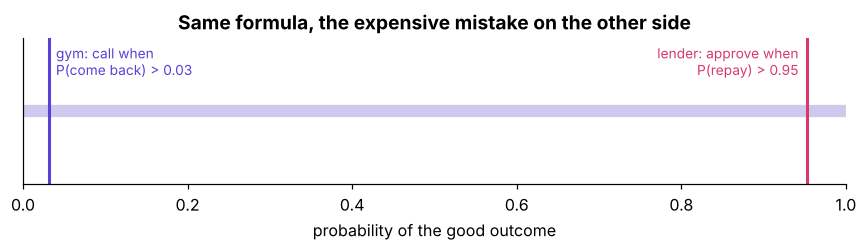

In [3]:
fig, ax = plt.subplots(figsize=(8, 2.4))
ax.axhline(0, color=LILAC, lw=8)
ax.axvline(0.032, color=VIOLET, lw=2); ax.text(0.04, 0.5, "gym: call when\nP(come back) > 0.03", color=VIOLET, fontsize=9)
ax.axvline(T_LEND, color=ROSE, lw=2); ax.text(T_LEND - 0.01, 0.5, "lender: approve when\nP(repay) > 0.95", color=ROSE, fontsize=9, ha="right")
ax.set_xlim(0, 1); ax.set_ylim(-1, 1); ax.set_yticks([]); ax.set_xlabel("probability of the good outcome")
ax.set_title("Same formula, the expensive mistake on the other side")
plt.tight_layout(); plt.show()

## What changes, what stays, what would leak?

| Changes | Stays | Would leak |
|---|---|---|
| The target: came back becomes repaid | Split first, seal the test, beat a baseline | Anything written after the decision |
| The costs, so the cut: 0.03 becomes 0.95 | The four boxes and the bill formula | An EMI bounce in month two |
| The moment of prediction: the call becomes the approval | The four-part justification | A collections flag |
| The weakest segment, found again | The monitoring rule's four parts | A column's name is never the test |

In [4]:
# Each column with the day it is written, counted from the approval decision (invented).
audit = pd.DataFrame({"column": ["monthly_income", "bureau_score", "loan_term_months", "emi_bounce_month2", "collections_flag"],
                      "written_day": [-30, -2, 0, 60, 90]})
audit["known at decision"] = audit.written_day <= 0
print(audit.to_string(index=False))
check("every column written after the decision is flagged", (~audit.loc[audit.written_day > 0, "known at decision"]).all())
check("the lending cut sits above 0.9 and the gym's below 0.1", T_LEND > 0.9 and 30 / 930 < 0.1)
check("the cost cut's bill is below the default 0.5 bill", lend_bill(T_LEND)["bill Rs"] < lend_bill(0.5)["bill Rs"])

           column  written_day  known at decision
   monthly_income          -30               True
     bureau_score           -2               True
 loan_term_months            0               True
emi_bounce_month2           60              False
 collections_flag           90              False
PASS  every column written after the decision is flagged
PASS  the lending cut sits above 0.9 and the gym's below 0.1
PASS  the cost cut's bill is below the default 0.5 bill


## What did this chapter establish?

| Question | Answer |
|---|---|
| The lending cut | 40,000 / 42,000 = 0.952 on P(repay) |
| What changes | Target, costs and cut, the moment of prediction, the weakest segment |
| What stays | The split, the baseline, the bill, the memo, the rule |
| What leaks | Anything written after the decision, whatever it is called |

Chapter 5 puts the whole justification in front of the people who will push on it.